In [1]:
import sys # for automation and parallelization: set manual to false when run by a launcher
import json
MANUAL, SCENARIO = (True, 'base') if 'ipykernel' in sys.argv[0]\
     else (False,  json.loads(sys.argv[1])['scenario'])

# START

In [2]:
sys.path.insert(0, r'../../../quetzal')

from quetzal.model import connectionscanmodel, stepmodel
from quetzal.io import excel
import numpy as np
import pandas as pd
import geopandas as gpd

import shapely

import matplotlib.pyplot as plt
from tqdm import tqdm

In [3]:
qpath = r'../../'
ipath = qpath + r'inputs/'
mpath = qpath + r'scenarios/{}/models/'.format(SCENARIO)

In [4]:
var = excel.read_var(ipath + r'parameters.xlsx', scenario=SCENARIO)

In [5]:
#if var['run_mode']['mode'] == 'timetables':
#    print('timetables scenario')
#    end_of_notebook

In [6]:
NTLEG_PENALTY = var[('pathfinders_general', 'ntleg_penalty')]
TRANSFER_DURATION = var[('pathfinders_general', 'transfer_duration')]
WALK_SPEED = var[('pathfinders_general', 'walk_speed')]
TRANSFER_PENALTY = var[('pathfinders_general', 'transfer_penalty')]

WALK_TIME_FACTOR = var[('mode_penalty', 'walk_time_factor')]
BIKE_TIME_FACTOR = var[('mode_penalty', 'bike_time_factor')]
CAR_TIME_FACTOR = var[('mode_penalty', 'car_time_factor')]
BOARDING_TIMES = var['boarding_time'].to_dict()

FLAT_FARES = var['fare'].to_dict()
KM_FARES = var['fare_km'].to_dict()

CAR_KM_FARES = var['fare_car'].to_dict()
KM_FARES['car'] = CAR_KM_FARES['fuel_cost'] + CAR_KM_FARES['other_costs']

BIKE_SPEED = var['bike_speed'].to_dict()
BIKE_FACTORS = {int(x.replace('k', '')): (1+y) for x, y in var['bike_factor'].to_dict().items()}
BIKE_FACTORS[0] = 0

VALUE_OF_TIME_SEC = var[('value_of_time', 'value_of_time_h')]/3600

INTRA_AREA_TO_DISTANCE_FACTOR = var[('step_distribution', 'intra_area_to_distance_factor')]

# READ

In [7]:
sm = stepmodel.read_zippedpickles(mpath + 'zones')

zones: 100%|██████████| 13/13 [00:00<00:00, 32.02it/s]   


In [ ]:
### ### For OD TEST
### zones_ = sm.zones.copy()
### sm.zones = gpd.GeoDataFrame(sm.zones.drop(columns='geometry').merge(sm.centroids[['NUM_ZONE', 'geometry']], on='NUM_ZONE'), crs='EPSG:2154')
### sm.zones.index = 'zone_' + sm.zones['NUM_ZONE'].apply(lambda x: f'0{x}' if x<10 else str(x))
### sm.zones.index.name = 'index'

# NODE CLUSTERING

In [9]:
sm.preparation_clusterize_nodes(
     distance_threshold=200
)

In [10]:
sm._add_type_prefixes(
        prefixes={'nodes': 'node_'}
    )

can not add prefixes on table:  footpaths


In [11]:
sm_bike = sm.copy()
sm_bike.road_links, sm_bike.road_nodes = sm_bike.road_links.loc[sm_bike.road_links['bike']], sm_bike.road_nodes.loc[sm_bike.road_nodes['bike']]

sm_car = sm.copy()
sm_car.road_links, sm_car.road_nodes = sm_car.road_links.loc[sm_car.road_links['bike']], sm_car.road_nodes.loc[sm_car.road_nodes['bike']]

# Walkmodels

In [12]:
sm.road_links['walk_speed'] = WALK_SPEED # km / h
sm.road_links['walk_time'] = sm.road_links.length / (sm.road_links['walk_speed'] / 3.6) * WALK_TIME_FACTOR

In [13]:
sm.preparation_ntlegs(
    zone_to_road=True,
    zone_to_transit=False,
    short_leg_speed=WALK_SPEED/WALK_TIME_FACTOR,
    long_leg_speed=WALK_SPEED/WALK_TIME_FACTOR
)

In [14]:
sm._add_type_prefixes(
    prefixes={
        'zone_to_road': 'ztr_',
        'road_to_transit': 'rtt_',
    }
)

# PATHFINDER - PT ONLY

In [15]:
# Access times
sm.links['time'] += sm.links['route_type'].map(BOARDING_TIMES).fillna(0)

In [16]:
# add fare in time for pathfinder to find most relevant paths
sm.links['km_fare'] = sm.links.length * sm.links.route_type.apply(lambda x: KM_FARES[x]) / 1000
sm.links['true_time'] = sm.links['time'].copy()
sm.links['time'] = sm.links['time'] + (sm.links['km_fare'] / VALUE_OF_TIME_SEC)

In [17]:
#sm.links['true_headway'] = sm.links['headway'].copy()
#sm.links['headway'] = sm.links['perceived_headway'].copy()


In [18]:
# pruning algorithm
sm.step_pt_pathfinder(
    broken_modes=True, broken_routes=True, route_column='trip_id',
    walk_on_road=True, keep_pathfinder=True
)

# remove intrazonal (handled differently)
sm.pt_los = sm.pt_los[sm.pt_los['origin']!=sm.pt_los['destination']]
sm.pt_los.reset_index(drop=True, inplace=True)

start publicpathfinder
68 sources 68 targets direct search
68 + 0 = 68 >= 0.5 * 68 keeping od_set
68 + 0 = 68 >= 0.5 * 68 keeping od_set
5 + 8 = 13 < 0.5 * 68 splitting od_set
8 + 68 = 76 >= 0.5 * 68 keeping od_set
68 + 0 = 68 >= 0.5 * 68 keeping od_set
68 + 0 = 68 >= 0.5 * 68 keeping od_set
68 + 0 = 68 >= 0.5 * 68 keeping od_set
8 + 4 = 12 >= 0.5 * 14 keeping od_set
1 + 2 = 3 >= 0.5 * 4 keeping od_set
5 + 0 = 5 >= 0.5 * 5 keeping od_set
2 + 8 = 10 >= 0.5 * 16 keeping od_set
2 + 3 = 5 < 0.5 * 11 splitting od_set
1 + 0 = 1 >= 0.5 * 1 keeping od_set
0 + 2 = 2 >= 0.5 * 2 keeping od_set
1 + 0 = 1 >= 0.5 * 1 keeping od_set
7 + 1 = 8 >= 0.5 * 13 keeping od_set
3 + 2 = 5 < 0.5 * 15 splitting od_set
5 + 5 = 10 < 0.5 * 22 splitting od_set
2 + 0 = 2 >= 0.5 * 2 keeping od_set
2 + 1 = 3 >= 0.5 * 3 keeping od_set
1 + 0 = 1 >= 0.5 * 1 keeping od_set
1 + 0 = 1 >= 0.5 * 1 keeping od_set
0 + 1 = 1 >= 0.5 * 1 keeping od_set
2 + 0 = 2 >= 0.5 * 2 keeping od_set
5 + 9 = 14 < 0.5 * 56 splitting od_set
1 + 0

  0%|          | 0/169 [00:00<?, ?it/s]

16 sources 14 targets transposed search


trip_id {'31_TBM_3_0'}:   2%|▏         | 3/169 [00:00<00:23,  6.95it/s]

4 sources 9 targets direct search
5 sources 55 targets direct search
57 sources 16 targets transposed search


trip_id {'31_TBM_3_1'}:   4%|▍         | 7/169 [00:00<00:16,  9.79it/s]

... (112 outputs left out)

68 sources 68 targets direct search
68 sources 68 targets direct search


route_type {'bus', 'rail'}: 100%|██████████| 7/7 [00:03<00:00,  1.87it/s]

68 sources 68 targets direct search
path_analysis



path_analysis: 100%|██████████| 32382/32382 [00:02<00:00, 15936.73it/s]


In [19]:
hierarchy = ['rail', 'tramway', 'bus', 'schoolbus', 'ferry', 'walk']
sm.analysis_pt_route_type(hierarchy)

In [20]:
# COMPUTE FARES
links_mode = {}
links_mode_lengths = {}
for mode in sm.links.route_type.unique():
    links = sm.links[sm.links.route_type==mode].index
    links_mode[mode] = links
    lengths = sm.links.loc[links]['length'].to_dict()
    links_mode_lengths[mode] = lengths

for k,v in links_mode.items():
    sm.pt_los[k + '_link_path'] = sm.pt_los['link_path'].apply(lambda x: [a for a in x if a in v])
    sm.pt_los[k + '_in_vehicle_length'] = sm.pt_los[k + '_link_path'].apply(lambda x: sum([links_mode_lengths[k][a] for a in x]))

sm.pt_los['fare'] = 0
sm.pt_los['flat_fare'] = 0
sm.pt_los['km_fare'] = 0

for m in links_mode.keys():
    sm.pt_los['fare'] += (sm.pt_los[m + '_in_vehicle_length']>0) * FLAT_FARES[m] +\
          sm.pt_los[m + '_in_vehicle_length'] * KM_FARES[m] / 1000
    sm.pt_los['flat_fare'] += (sm.pt_los[m + '_in_vehicle_length']>0) * FLAT_FARES[m]
    sm.pt_los['km_fare'] += sm.pt_los[m + '_in_vehicle_length'] * KM_FARES[m] / 1000

sm.pt_los['parking_fare'] = 0

# PATHFINDER - PT + BIKE

In [21]:
sm_bike_pt = sm.copy()

In [22]:
### Connexion possible seulement avec le train, créer des liens d'accès à vitesse vélo et 
# des liens de diffusion à vitesse de marche (les gens laissent leur vélo à la gare de départ)
# Pour le moment on ne calcule pas l'utilité des connecteurs vélo en coût généralisé mais simplement en temps.

In [23]:
sm_bike_pt.road_links = sm_bike_pt.road_links.loc[sm_bike_pt.road_links['bike']]
sm_bike_pt.road_nodes = sm_bike_pt.road_nodes.loc[sm_bike_pt.road_nodes['bike']]

sm_bike_pt.links = sm_bike_pt.links.loc[sm_bike_pt.links['route_type'] == 'rail']
sm_bike_pt.nodes = sm_bike_pt.nodes.loc[list(set(sm_bike_pt.links['a'].values.tolist() + sm_bike_pt.links['b'].values.tolist()))]

sm_bike_pt.integrity_fix_road_network()

direct: 57535it [00:01, 31437.52it/s]
reversed: 57535it [00:01, 38543.60it/s]
57404it [00:01, 36029.77it/s]


In [24]:
### Idée développer un réseau d'accès et un réseau de diffusion.
# Tous les connecteurs en accès rejoignent le réseau d'accès (vélo)
# Tous les connecteurs en diffusion partent du réseau de diffusion (marche à pied)
# Tous les connecteurs au réseau routier existent pour les deux réseaux
# --> problème : plus personne ne prend le train, l'attente est trop importante, il est plus interessant de se déplacer en vélo
# --             jusqu'à la destination finale, ne marche pas si le train est plus lent que la voiture/le vélo, dans ce cas
# --             l'itinéraire préféré est celui qui va en voiture à la station pour y changer de mode -> Ca ne marche pas


### sm_bike_pt.preparation_ntlegs(
###     zone_to_road=True,
###     zone_to_transit=False,
###     road_to_transit=True
### )
### 
### sm_bike_pt._add_type_prefixes(
###     prefixes={
###         'zone_to_road': 'ztr_',
###         'road_to_transit': 'rtt_',
###     }
### )
### 
### inbound_road_links = sm_bike_pt.road_links.copy()
### inbound_road_nodes = sm_bike_pt.road_nodes.copy()
### road_to_transit_inbound = sm_bike_pt.road_to_transit.copy()
### 
### ### Rlinks
### inbound_road_links.index += '_a'
### inbound_road_links['a'] += '_a'
### inbound_road_links['b'] += '_a'
### ### TODO : ajouter la définition du temps en fonction des coefficients kappa
### inbound_road_links['walk_speed'] = inbound_road_links.apply(lambda x: max(x['speed']*BIKE_SPEED['bike_speed_factor_no_infra'], BIKE_SPEED['max_bike_speed_no_infra']) if (x['bike_index'] < 2) else BIKE_SPEED['bike_speed_infra'], 1)
### inbound_road_links['walk_time'] = inbound_road_links['length']/inbound_road_links['speed']*3.6
### 
### ### Rnodes
### inbound_road_nodes.index += '_a'
### 
### ### RoadToTransit
### road_to_transit_inbound.index += '_a'
### road_to_transit_inbound.loc[road_to_transit_inbound['direction'] == 'access', 'b'] += '_a'
### road_to_transit_inbound.loc[road_to_transit_inbound['direction'] == 'eggress', 'a'] += '_a'
### 
### ### ZoneToTransit
### sm_bike_pt.zone_to_road.loc[sm_bike_pt.zone_to_road['direction'] == 'access', 'b'] += '_a'
### 
### ### Concat
### sm_bike_pt.road_links = pd.concat([sm_bike_pt.road_links, inbound_road_links])
### sm_bike_pt.road_nodes = pd.concat([sm_bike_pt.road_nodes, inbound_road_nodes])
### sm_bike_pt.road_to_transit = pd.concat([sm_bike_pt.road_to_transit, road_to_transit_inbound])
### 
### ### PathFinder
### sm_bike_pt.step_pt_pathfinder(
###     broken_modes=False, broken_routes=False,
###     walk_on_road=True
### )
### sm_bike_pt.analysis_pt_route_type(['rail', 'bike'])
### 
### # remove intrazonal (handled differently)
### sm_bike_pt.pt_los = sm_bike_pt.pt_los[sm_bike_pt.pt_los['origin']!=sm_bike_pt.pt_los['destination']]
### sm_bike_pt.pt_los.reset_index(drop=True, inplace=True)

In [25]:
### Idée utiliser les deux tailles de connecteurs

sm_bike_pt.preparation_ntlegs(
    zone_to_road=False,
    zone_to_transit=True,
    road_to_transit=False,
    n_ntlegs = 10,
    max_ntleg_length = 10000
)

sm_bike_pt._add_type_prefixes(
    prefixes={
        'zone_to_transit': 'ztt_'
    }
)

sm_bike_pt.preparation_footpaths(speed=WALK_SPEED/WALK_TIME_FACTOR, max_length=500)

sm_bike_pt.zone_to_transit.loc[sm_bike_pt.zone_to_transit['direction'] == 'access', 'speed'] = BIKE_SPEED['max_bike_speed_no_infra']/BIKE_TIME_FACTOR
sm_bike_pt.zone_to_transit.loc[sm_bike_pt.zone_to_transit['direction'] == 'eggress', 'speed'] = WALK_SPEED/WALK_TIME_FACTOR

sm_bike_pt.zone_to_transit['time'] = sm_bike_pt.zone_to_transit['distance']/sm_bike_pt.zone_to_transit['speed']*3.6

sm_bike_pt.step_pt_pathfinder(
    broken_modes=False, broken_routes=False,
    walk_on_road=True
)

sm_bike_pt.analysis_pt_route_type(['rail', 'bike'])

# remove intrazonal (handled differently)
sm_bike_pt.pt_los = sm_bike_pt.pt_los[sm_bike_pt.pt_los['origin']!=sm_bike_pt.pt_los['destination']]
sm_bike_pt.pt_los.reset_index(drop=True, inplace=True)

start publicpathfinder
68 sources 68 targets direct search
path_analysis


path_analysis: 100%|██████████| 4624/4624 [00:00<00:00, 42338.96it/s]


In [26]:
sm_bike_pt.pt_los = sm_bike_pt.pt_los.loc[sm_bike_pt.pt_los['route_type'] == 'rail']
sm_bike_pt.pt_los['pathfinder_session'] = 'bike_pt'

In [27]:
# COMPUTE FARES
links_mode = {}
links_mode_lengths = {}
for mode in sm_bike_pt.links.route_type.unique():
    links = sm_bike_pt.links[sm_bike_pt.links.route_type==mode].index
    links_mode[mode] = links
    lengths = sm_bike_pt.links.loc[links]['length'].to_dict()
    links_mode_lengths[mode] = lengths

for k,v in links_mode.items():
    sm_bike_pt.pt_los[k + '_link_path'] = sm_bike_pt.pt_los['link_path'].apply(lambda x: [a for a in x if a in v])
    sm_bike_pt.pt_los[k + '_in_vehicle_length'] = sm_bike_pt.pt_los[k + '_link_path'].apply(lambda x: sum([links_mode_lengths[k][a] for a in x]))

sm_bike_pt.pt_los['fare'] = 0
sm_bike_pt.pt_los['km_fare'] = 0
sm_bike_pt.pt_los['flat_fare'] = 0

for m in links_mode.keys():
    sm_bike_pt.pt_los['fare'] += (sm_bike_pt.pt_los[m + '_in_vehicle_length']>0) * FLAT_FARES[m] +\
          sm_bike_pt.pt_los[m + '_in_vehicle_length'] * KM_FARES[m] / 1000
    sm_bike_pt.pt_los['flat_fare'] += (sm_bike_pt.pt_los[m + '_in_vehicle_length']>0) * FLAT_FARES[m]
    sm_bike_pt.pt_los['km_fare'] += sm_bike_pt.pt_los[m + '_in_vehicle_length'] * KM_FARES[m] / 1000

sm_bike_pt.pt_los['parking_fare'] = 0

# PATHFINDER PT + VP

In [28]:
sm_car_pt = sm.copy()

In [29]:
### Connexion possible seulement avec le train, créer des liens d'accès à vitesse vélo et 
# des liens de diffusion à vitesse de marche (les gens laissent leur vélo à la gare de départ)
# Pour le moment on ne calcule pas l'utilité des connecteurs vélo en coût généralisé mais simplement en temps.

In [30]:
sm_car_pt.links = sm_car_pt.links.loc[sm_car_pt.links['route_type'] == 'rail']
sm_car_pt.nodes = sm_car_pt.nodes.loc[list(set(sm_car_pt.links['a'].values.tolist() + sm_car_pt.links['b'].values.tolist()))]

sm_car_pt.integrity_fix_road_network()

direct: 58218it [00:01, 38509.64it/s]
reversed: 58218it [00:01, 31786.64it/s]
58218it [00:01, 39565.52it/s]


In [31]:
### ### Idée développer un réseau d'accès et un réseau de diffusion.
### # Tous les connecteurs en accès rejoignent le réseau d'accès (vélo)
### # Tous les connecteurs en diffusion partent du réseau de diffusion (marche à pied)
### # Tous les connecteurs au réseau routier existent pour les deux réseaux

### sm_car_pt.preparation_ntlegs(
###     zone_to_road=True,
###     zone_to_transit=False,
###     road_to_transit=True
### )
### 
### sm_car_pt._add_type_prefixes(
###     prefixes={
###         'zone_to_road': 'ztr_',
###         'road_to_transit': 'rtt_',
###     }
### )
### 
### inbound_road_links = sm_car_pt.road_links.copy()
### inbound_road_nodes = sm_car_pt.road_nodes.copy()
### road_to_transit_inbound = sm_car_pt.road_to_transit.copy()
### 
### inbound_road_links = inbound_road_links.loc[inbound_road_links['car']]
### inbound_road_links.index += '_a'
### inbound_road_links['a'] += '_a'
### inbound_road_links['b'] += '_a'
### 
### inbound_road_links['walk_speed'] = inbound_road_links['speed']
### inbound_road_links['walk_time'] = inbound_road_links['time']
### 
### inbound_road_nodes = inbound_road_nodes.loc[inbound_road_nodes['car']]
### inbound_road_nodes.index += '_a'
### 
### road_to_transit_inbound.index += '_a'
### road_to_transit_inbound.loc[road_to_transit_inbound['direction'] == 'access', 'b'] += '_a'
### road_to_transit_inbound.loc[road_to_transit_inbound['direction'] == 'eggress', 'a'] += '_a'
### 
### sm_car_pt.zone_to_road.loc[sm_car_pt.zone_to_road['direction'] == 'access', 'b'] += '_a'
### 
### sm_car_pt.road_links = pd.concat([sm_car_pt.road_links, inbound_road_links])
### sm_car_pt.road_nodes = pd.concat([sm_car_pt.road_nodes, inbound_road_nodes])
### sm_car_pt.road_to_transit = pd.concat([sm_car_pt.road_to_transit, road_to_transit_inbound])
### 
### sm_car_pt.step_pt_pathfinder(
###     broken_modes=False, broken_routes=False,
###     walk_on_road=True
### )
### 
### sm_car_pt.analysis_pt_route_type(['car', 'bike'])
### 
### # remove intrazonal (handled differently)
### sm_car_pt.pt_los = sm_car_pt.pt_los[sm_car_pt.pt_los['origin']!=sm_car_pt.pt_los['destination']]
### sm_car_pt.pt_los.reset_index(drop=True, inplace=True)

In [32]:
### Idée utiliser les deux tailles de connecteurs

sm_car_pt.preparation_ntlegs(
    zone_to_road=False,
    zone_to_transit=True,
    road_to_transit=False,
    n_ntlegs = 10,
    max_ntleg_length = 10000
)

sm_car_pt._add_type_prefixes(
    prefixes={
        'zone_to_transit': 'ztt_'
    }
)

sm_car_pt.preparation_footpaths(speed=WALK_SPEED/WALK_TIME_FACTOR, max_length=500)

sm_car_pt.zone_to_transit.loc[sm_car_pt.zone_to_transit['direction'] == 'access', 'speed'] = 40 ### arbitrary car speed atcf
sm_car_pt.zone_to_transit.loc[sm_car_pt.zone_to_transit['direction'] == 'eggress', 'speed'] = WALK_SPEED/WALK_TIME_FACTOR

sm_car_pt.zone_to_transit['time'] = sm_car_pt.zone_to_transit['distance']/sm_car_pt.zone_to_transit['speed']*3.6

sm_car_pt.step_pt_pathfinder(
    broken_modes=False, broken_routes=False,
    walk_on_road=True
)

sm_car_pt.analysis_pt_route_type(['rail', 'bike'])

# remove intrazonal (handled differently)
sm_car_pt.pt_los = sm_car_pt.pt_los[sm_car_pt.pt_los['origin']!=sm_car_pt.pt_los['destination']]
sm_car_pt.pt_los.reset_index(drop=True, inplace=True)

start publicpathfinder
68 sources 68 targets direct search
path_analysis


path_analysis: 100%|██████████| 4624/4624 [00:00<00:00, 40329.85it/s]


In [33]:
sm_car_pt.pt_los = sm_car_pt.pt_los.loc[sm_car_pt.pt_los['route_type'] == 'rail']
sm_car_pt.pt_los['pathfinder_session'] = 'car_pt'

In [34]:
# COMPUTE FARES
links_mode = {}
links_mode_lengths = {}
for mode in sm_car_pt.links.route_type.unique():
    links = sm_car_pt.links[sm_car_pt.links.route_type==mode].index
    links_mode[mode] = links
    lengths = sm_car_pt.links.loc[links]['length'].to_dict()
    links_mode_lengths[mode] = lengths

for k,v in links_mode.items():
    sm_car_pt.pt_los[k + '_link_path'] = sm_car_pt.pt_los['link_path'].apply(lambda x: [a for a in x if a in v])
    sm_car_pt.pt_los[k + '_in_vehicle_length'] = sm_car_pt.pt_los[k + '_link_path'].apply(lambda x: sum([links_mode_lengths[k][a] for a in x]))

sm_car_pt.pt_los['fare'] = 0
sm_car_pt.pt_los['km_fare'] = 0
sm_car_pt.pt_los['flat_fare'] = 0

for m in links_mode.keys():
    sm_car_pt.pt_los['fare'] += (sm_car_pt.pt_los[m + '_in_vehicle_length']>0) * FLAT_FARES[m] +\
          sm_car_pt.pt_los[m + '_in_vehicle_length'] * KM_FARES[m] / 1000
    sm_car_pt.pt_los['flat_fare'] += (sm_car_pt.pt_los[m + '_in_vehicle_length']>0) * FLAT_FARES[m]
    sm_car_pt.pt_los['km_fare'] += sm_car_pt.pt_los[m + '_in_vehicle_length'] * KM_FARES[m] / 1000

sm_car_pt.pt_los['parking_fare'] = 0 ### Parking gratuit au parking relais ?

# Correct times

In [35]:
# TC
sm.links['pathfinder_time'] = sm.links['time']
sm.links['time'] = sm.links['true_time']
sm.road_links['walk_time'] *= 1 / WALK_TIME_FACTOR
sm.zone_to_road['time'] *= 1 / WALK_TIME_FACTOR
sm.analysis_pt_time(boarding_time=0, walk_on_road=True)

# Vélo + TC
### TODO: séparer le temps marché (diffusion) du temps à vélo (accès)
sm_bike_pt.links['pathfinder_time'] = sm_bike_pt.links['time']
sm_bike_pt.links['time'] = sm_bike_pt.links['true_time']
sm_bike_pt.zone_to_road['time'] *= 1 / BIKE_TIME_FACTOR
sm_bike_pt.analysis_pt_time(boarding_time=0, walk_on_road=True)

### TODO: CAR + TC
sm_car_pt.links['pathfinder_time'] = sm_car_pt.links['time']
sm_car_pt.links['time'] = sm_car_pt.links['true_time']
sm_car_pt.analysis_pt_time(boarding_time=0, walk_on_road=True)

In [36]:
sm.pt_los = pd.concat([sm.pt_los, sm_bike_pt.pt_los, sm_car_pt.pt_los])

In [37]:
### sm.links['headway'] = sm.links['true_headway'].copy()
### sm.links.drop(columns='true_headway', inplace=True)

# ROAD PATHFINDER | car

In [38]:
sm_car = sm.copy()
sm_car.road_links = sm_car.road_links.loc[sm_car.road_links['car']]
sm_car.road_nodes = sm_car.road_nodes.loc[sm_car.road_nodes['car']]

sm_car.integrity_fix_road_network()

direct: 52960it [00:01, 36481.02it/s]
reversed: 52960it [00:01, 37958.07it/s]


Reached max recursive_depth


In [39]:
# empty volumes
sm_car.volumes = pd.DataFrame(index=pd.MultiIndex.from_product([sm_car.zones.index]*2))
sm_car.volumes.index.names = ['origin', 'destination']
sm_car.volumes.reset_index(inplace=True)

In [40]:
sm_car.preparation_ntlegs(
    zone_to_road=True,
    zone_to_transit=False,
    short_leg_speed=30,
    long_leg_speed=30
)

sm_car._add_type_prefixes(
    prefixes={
        'zone_to_road': 'ztr_'
    }
)

In [41]:
sm_car.step_road_pathfinder(method='aon')
# remove intrazonal (handled differently)
sm_car.car_los = sm_car.car_los[sm_car.car_los['origin']!=sm_car.car_los['destination']]
sm_car.car_los['pathfinder_session'] = 'car_aon'

In [42]:
sm_car.analysis_car_los()
sm_car.analysis_car_length()

In [43]:
sm.links

,a,trip_id,link_sequence,b,time,headway,pattern_id,route_id,service_id,trip_headsign,...,ineo_nomc,departure_time,arrival_time,speed,geometry,disaggregated_a,disaggregated_b,km_fare,true_time,pathfinder_time
index,,,,,,,,,,,,,,,,,,,,,
link_2_1104,node_2511,10_Calibus (Libourne)_3_0,1,node_1783,420.0,7200,CA_DU_LIBOURNAIS:Line:80_0,10_Calibus (Libourne)_3,CA_DU_LIBOURNAIS:Timetable:11,Libourne Gares,...,None,NaN,NaN,10.331566,"LINESTRING (441767.83 6442270.609, 442162.129 ...",node_2_MOBIITI:Quay:105050,node_2_MOBIITI:Quay:105051,0.433590,420.0,732.184829
link_2_1105,node_1783,10_Calibus (Libourne)_3_0,2,node_1592,480.0,7200,CA_DU_LIBOURNAIS:Line:80_0,10_Calibus (Libourne)_3,CA_DU_LIBOURNAIS:Timetable:11,Libourne Gares,...,None,NaN,NaN,11.826338,"LINESTRING (442162.129 6437952.674, 444260.973...",node_2_MOBIITI:Quay:105051,node_2_MOBIITI:Quay:95616,0.567231,480.0,888.406524
link_2_1106,node_1592,10_Calibus (Libourne)_3_0,3,node_2558,60.0,7200,CA_DU_LIBOURNAIS:Line:80_0,10_Calibus (Libourne)_3,CA_DU_LIBOURNAIS:Timetable:11,Libourne Gares,...,None,NaN,NaN,3.236396,"LINESTRING (444260.973 6432682.95, 444251.902 ...",node_2_MOBIITI:Quay:95616,node_2_MOBIITI:Quay:82632,0.019404,60.0,73.970632
link_2_1107,node_2558,10_Calibus (Libourne)_3_0,4,node_1592,60.0,7200,CA_DU_LIBOURNAIS:Line:80_0,10_Calibus (Libourne)_3,CA_DU_LIBOURNAIS:Timetable:11,Libourne Gares,...,None,NaN,NaN,3.191227,"LINESTRING (444251.902 6432489.126, 444268.105...",node_2_MOBIITI:Quay:82632,node_2_MOBIITI:Quay:95615,0.019133,60.0,73.775648
link_2_1108,node_1592,10_Calibus (Libourne)_3_0,5,node_1977,60.0,7200,CA_DU_LIBOURNAIS:Line:80_0,10_Calibus (Libourne)_3,CA_DU_LIBOURNAIS:Timetable:11,Libourne Gares,...,None,NaN,NaN,11.238462,"LINESTRING (444268.105 6432679.767, 444849.181...",node_2_MOBIITI:Quay:95615,node_2_MOBIITI:Quay:82268,0.067380,60.0,108.513286
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
link_5_4222,node_815,R470_Cars Régionaux 33 - Gironde_3_0,12,node_611,360.0,14400,GIRONDE:Line:2768_0,R470_Cars Régionaux 33 - Gironde_3,GIRONDE:Timetable:4144,R470-01-A,...,None,NaN,NaN,1.906426,"LINESTRING (418787.849 6421104.539, 418354.746...",node_5_MOBIITI:Quay:103790,node_5_MOBIITI:Quay:103795,0.068592,360.0,409.385943
link_5_4223,node_611,R470_Cars Régionaux 33 - Gironde_3_0,13,node_43,240.0,14400,GIRONDE:Line:2768_0,R470_Cars Régionaux 33 - Gironde_3,GIRONDE:Timetable:4144,R470-01-A,...,None,NaN,NaN,3.148069,"LINESTRING (418354.746 6421636.425, 417614.552...",node_5_MOBIITI:Quay:103795,node_5_MOBIITI:Quay:103793,0.075510,240.0,294.367243
link_5_4224,node_43,R470_Cars Régionaux 33 - Gironde_3_0,14,node_114,120.0,14400,GIRONDE:Line:2768_0,R470_Cars Régionaux 33 - Gironde_3,GIRONDE:Timetable:4144,R470-01-A,...,None,NaN,NaN,3.457635,"LINESTRING (417614.552 6421487.123, 417199.939...",node_5_MOBIITI:Quay:103793,node_5_MOBIITI:Quay:103921,0.041468,120.0,149.856823


# ROAD PATHFINDER | bike

In [44]:
sm_bike = sm.copy()
sm_bike.road_links = sm_bike.road_links.loc[sm_bike.road_links['bike']]
sm_bike.road_nodes = sm_bike.road_nodes.loc[sm_bike.road_nodes['bike']]

sm_bike.integrity_fix_road_network()

direct: 57535it [00:01, 38005.53it/s]
reversed: 57535it [00:01, 38611.62it/s]
57404it [00:01, 38360.49it/s]


In [45]:
# Pour l'instant, on ne fait le pathfinder qu'avec un plus court chemin facile, ensuite on intégrera 
# les constantes de Royston en vitesse ce qui permettra de faire quelque chose de super.

In [46]:
sm_bike.road_links['speed'] = sm_bike.road_links.apply(lambda x: max(x['speed']*BIKE_SPEED['bike_speed_factor_no_infra'], BIKE_SPEED['max_bike_speed_no_infra']) if (x['bike_index'] < 2) else BIKE_SPEED['bike_speed_infra'], 1)
sm_bike.road_links['time'] = sm_bike.road_links['length']/sm_bike.road_links['speed']*3.6

In [47]:
# empty volumes
sm_bike.volumes = pd.DataFrame(index=pd.MultiIndex.from_product([sm.zones.index]*2))
sm_bike.volumes.index.names = ['origin', 'destination']
sm_bike.volumes.reset_index(inplace=True)

In [48]:
sm_bike.preparation_ntlegs(
    zone_to_road=True,
    zone_to_transit=False,
    short_leg_speed=BIKE_SPEED['max_bike_speed_no_infra']/BIKE_TIME_FACTOR,
    long_leg_speed=BIKE_SPEED['max_bike_speed_no_infra']/BIKE_TIME_FACTOR
)

sm_bike._add_type_prefixes(
    prefixes={
        'zone_to_road': 'ztr_'
    }
)

In [49]:
sm_bike.step_road_pathfinder(method='aon')
# remove intrazonal (handled differently)
sm_bike.car_los = sm_bike.car_los[sm_bike.car_los['origin']!=sm_bike.car_los['destination']]
sm_bike.car_los['pathfinder_session'] = 'bike_aon'

In [50]:
sm_bike.analysis_car_los()
sm_bike.analysis_car_length()

# INTRAZONAL

In [51]:
# empty volumes
sm.volumes = pd.DataFrame(index=pd.MultiIndex.from_product([sm.zones.index]*2))
sm.volumes.index.names = ['origin', 'destination']
sm.volumes.reset_index(inplace=True)

In [52]:
sm.zone_length = (sm.zones.area ** 0.5) * INTRA_AREA_TO_DISTANCE_FACTOR

In [53]:
def set_intra_los(mode, speed_kmh, km_fare, base_fare=0, time_penalty=0):
    intra_los = sm.volumes[sm.volumes['origin']==sm.volumes['destination']].copy()

    intra_los['route_type'] = mode
    if mode != 'walk':
        intra_los['route_types'] = [(mode,)]*len(intra_los)
    else:
        intra_los['route_types'] = [tuple()]*len(intra_los)

    intra_los['length'] = intra_los['origin'].apply(lambda x: sm.zone_length[x])
    intra_los['gtime'] = intra_los['origin'].apply(
        lambda x: sm.zone_length[x] / (speed_kmh / 3.6)
    )
    intra_los['gtime'] += time_penalty
    intra_los['time'] = intra_los['gtime']
    intra_los['fare'] = intra_los['origin'].apply(
        lambda x: sm.zone_length[x] * km_fare / 1000 + base_fare
    )
    intra_los['pathfinder_session'] = 'intrazonal'
    intra_los['ntransfers'] = 0
    intra_los['path'] = intra_los['origin'].apply(lambda x: tuple([x]))

    for col in ['node_path', 'link_path', 'boardings', 'alightings',
        'footpaths', 'ntlegs', 'boarding_links', 'alighting_links', 'transfers']:
            intra_los[col] = [tuple()]*len(intra_los)

    return intra_los

sm.intra_los = pd.concat(
    [
        set_intra_los('car', 40/CAR_TIME_FACTOR, KM_FARES['car'], base_fare=0),
        set_intra_los('bike', BIKE_SPEED['max_bike_speed_no_infra']/BIKE_TIME_FACTOR, 0),
        set_intra_los('walk', WALK_SPEED/WALK_TIME_FACTOR, 0)
    ]
)

sm.intra_los.reset_index(drop=True, inplace=True)

In [54]:
sm.intra_los['flat_fare'] = 0
sm.intra_los['km_fare'] = sm.intra_los['fare'].copy()

sm.intra_los['parking_fare'] = 0
sm.intra_los.loc[sm.intra_los['route_type'] == 'car', 'parking_fare'] = sm.intra_los.loc[sm.intra_los['route_type'] == 'car', 'destination'].map(sm.zones['parking_fare'].to_dict())
sm.intra_los['fare'] += sm.intra_los['parking_fare']

# CONCAT

In [55]:
# CAR
sm_car.car_los['penalties'] = 0
sm_car.car_los['ntransfers'] = 0
sm_car.car_los['parking_fare'] = sm_car.car_los['destination'].map(sm_car.zones['parking_fare'].to_dict())
sm_car.car_los['flat_fare'] = 0
sm_car.car_los['km_fare'] = sm_car.car_los['length'] * KM_FARES['car'] / 1000 
sm_car.car_los['fare'] = sm_car.car_los['length'] * KM_FARES['car'] / 1000 + sm_car.car_los['parking_fare']
sm_car.car_los['gtime'] *= CAR_TIME_FACTOR
sm_car.car_los['gtime'] += sm_car.car_los['penalties']
sm_car.car_los['route_types'] = [('car',)] * len(sm_car.car_los)
sm_car.car_los['route_type'] = 'car'
sm_car.car_los['time'] = sm_car.car_los['gtime']
sm_car.car_los['gtime'] += sm_car.car_los['in_vehicle_length'] / 1000 * KM_FARES['car'] / VALUE_OF_TIME_SEC

# BIKE
sm_bike.car_los['penalties'] = 0
sm_bike.car_los['ntransfers'] = 0
sm_bike.car_los['parking_fare'] = 0
sm_bike.car_los['flat_fare'] = 0
sm_bike.car_los['km_fare'] = 0
sm_bike.car_los['fare'] = 0
sm_bike.car_los['gtime'] *= BIKE_TIME_FACTOR
sm_bike.car_los['gtime'] += sm_bike.car_los['penalties']
sm_bike.car_los['route_types'] = [('bike',)] * len(sm_bike.car_los)
sm_bike.car_los['route_type'] = 'bike'
sm_bike.car_los['time'] = sm_bike.car_los['gtime']

sm.los = pd.concat([sm_car.car_los, sm_bike.car_los, sm.pt_los, sm.intra_los]).reset_index(drop=True)

In [56]:
sm_car.car_los[['km_fare', 'time', 'gtime']]

,km_fare,time,gtime
1,6.857163,1417.509268,6290.737897
2,19.190731,3299.841733,17037.291198
3,23.337230,4678.357626,21445.842289
4,16.393243,2685.654717,14455.882116
5,4.867722,1532.965527,4980.365196
...,...,...,...
4618,2.012988,726.641538,2134.877071
4619,1.481471,567.477631,1591.683002
4620,0.896674,337.492449,933.508086
4621,0.303055,115.924294,302.596494


# EXPORT

In [57]:
print(sm.los['route_types'].unique())

sm.to_zippedpickles(
    mpath + r'pathfinders',
    omitted_attributes=['pt_los', 'car_los', 'intra_los']
)

[('car',) ('bike',) ('bus',) ('tramway',) ('bus', 'tramway')
 ('rail', 'tramway') ('bus', 'rail', 'tramway') () ('bus', 'rail')
 ('rail',)]


los: 100%|██████████| 24/24 [00:05<00:00,  4.73it/s]            


In [58]:
mpath + r'pathfinders'

'../../scenarios/base/models/pathfinders'

In [59]:
end_of_notebook

NameError: name 'end_of_notebook' is not defined

In [61]:
sm.los.loc[sm.los['pathfinder_session'] == 'car_aon'][['time', 'fare']]

,time,fare
0,1417.509268,6.857163
1,3299.841733,19.190731
2,4678.357626,23.337230
3,2685.654717,16.393243
4,1532.965527,4.867722
...,...,...
4551,726.641538,2.012988
4552,567.477631,1.481471
4553,337.492449,2.696674
4554,115.924294,2.803055


## Calibration OD

In [ ]:
### sm_save = sm.copy()
sm = sm_save.copy()

In [ ]:
pd.set_option('display.max_columns', None)

In [ ]:
networks = {
    'best_path': 'pt',
    'mode_breaker': 'pt',
    'route_breaker': 'pt',
    'bike_pt': 'bike_pt',
    'car_pt': 'car_pt',
    'car_aon': 'car_aon',
    'bike_aon': 'bike_aon',
    'intrazonal': 'intrazonal'
}

In [ ]:
sm.los['journey_id'] = 'journey_' + sm.los.index.astype(str)

In [ ]:
od_route_components = sm.los[['journey_id', 'origin', 'pathfinder_session', 'destination', 'gtime', 'link_path', 'ntlegs', 'footpaths']]
od_route_components['pathfinder_session'] = od_route_components['pathfinder_session'].map(networks)

In [ ]:
od_links = od_route_components.drop(columns=['ntlegs', 'footpaths']).copy()
#od_links = od_links.drop(columns=['origin', 'destination'])
od_links = od_links.explode('link_path')

od_links = od_links.merge(sm.links[['trip_id', 'route_type', 'perceived_headway', 'route_color', 'geometry', 'time', 'speed']], left_on='link_path', right_index=True)
od_links.rename(columns={'perceived_headway': 'headway', 'link_path': 'index'}, inplace=True)
od_links['type'] = 'link'

In [ ]:
od_rlinks = od_route_components.loc[od_route_components['pathfinder_session'] == 'car_aon'].drop(columns=['ntlegs', 'footpaths']).copy()
#od_links = od_links.drop(columns=['origin', 'destination'])
od_rlinks = od_rlinks.explode('link_path')

od_rlinks = od_rlinks.merge(sm_car.road_links[['geometry', 'time', 'speed']], left_on='link_path', right_index=True)
od_rlinks['trip_id'] = 'car'
od_rlinks['route_type'] = 'car'
od_rlinks['route_color'] = '112563'
od_rlinks['headway'] = 0
od_rlinks.rename(columns={'link_path': 'index'}, inplace=True)
od_rlinks['type'] = 'car_link'

In [ ]:
od_blinks = od_route_components.loc[od_route_components['pathfinder_session'] == 'bike_aon'].drop(columns=['ntlegs', 'footpaths']).copy()
#od_links = od_links.drop(columns=['origin', 'destination'])
od_blinks = od_blinks.explode('link_path')

od_blinks = od_blinks.merge(sm_bike.road_links[['geometry', 'time', 'speed']], left_on='link_path', right_index=True)
od_blinks['trip_id'] = 'bike'
od_blinks['route_type'] = 'bike'
od_blinks['route_color'] = '262626'
od_blinks['headway'] = 0
od_blinks.rename(columns={'link_path': 'index'}, inplace=True)
od_blinks['type'] = 'bike_link'

In [ ]:
od_ntlegs = od_route_components.drop(columns=['link_path', 'footpaths']).copy()
#od_ntlegs = od_ntlegs.drop(columns=['origin', 'destination'])
od_ntlegs = od_ntlegs.explode('ntlegs')

road_to_transit_ = sm.road_to_transit.copy()
road_to_transit_['direction'] = 'access/eggress/transfer'
ntlegs_pt = pd.concat([sm.zone_to_road, road_to_transit_])
ntlegs_pt['pathfinder_session'] = 'pt'
ntlegs_pt_dict = ntlegs_pt.reset_index().set_index(['a', 'b'])['index'].to_dict()

ntlegs_bike = sm_bike_pt.zone_to_transit
ntlegs_bike['pathfinder_session'] = 'bike_pt'
ntlegs_bike_dict = ntlegs_bike.reset_index().set_index(['a', 'b'])['index'].to_dict()

ntlegs_car = sm_car_pt.zone_to_transit
ntlegs_car['pathfinder_session'] = 'car_pt'
ntlegs_car_dict = ntlegs_car.reset_index().set_index(['a', 'b'])['index'].to_dict()

od_ntlegs.loc[od_ntlegs['pathfinder_session'] == 'pt', 'ntlegs'] = od_ntlegs.loc[od_ntlegs['pathfinder_session'] == 'pt', 'ntlegs'].apply(ntlegs_pt_dict.get)
od_ntlegs.loc[od_ntlegs['pathfinder_session'] == 'bike_pt', 'ntlegs'] = od_ntlegs.loc[od_ntlegs['pathfinder_session'] == 'bike_pt', 'ntlegs'].apply(ntlegs_bike_dict.get)
od_ntlegs.loc[od_ntlegs['pathfinder_session'] == 'car_pt', 'ntlegs'] = od_ntlegs.loc[od_ntlegs['pathfinder_session'] == 'car_pt', 'ntlegs'].apply(ntlegs_car_dict.get)

ntlegs = pd.concat([ntlegs_pt, ntlegs_bike, ntlegs_car]).reset_index()[['index', 'direction', 'pathfinder_session', 'geometry', 'time', 'speed']]
od_ntlegs = od_ntlegs.merge(ntlegs, left_on=['ntlegs', 'pathfinder_session'], right_on=['index', 'pathfinder_session'])

od_ntlegs = od_ntlegs.drop(columns='ntlegs')
od_ntlegs['type'] = 'ntleg'

od_ntlegs['route_type'] = 'walk'
od_ntlegs.loc[(od_ntlegs['pathfinder_session'] == 'car_pt') & (od_ntlegs['direction'] == 'access'), 'route_type'] = 'car'
od_ntlegs.loc[(od_ntlegs['pathfinder_session'] == 'bike_pt') & (od_ntlegs['direction'] == 'access'), 'route_type'] = 'bike'

od_ntlegs.rename(columns={'direction': 'trip_id'}, inplace=True)

mode_colors = {
    'walk': '555555',
    'bike': '262626',
    'car': '112563'
}

od_ntlegs['headway'] = 0
od_ntlegs['route_color'] = od_ntlegs['route_type'].map(mode_colors)

In [ ]:
od_footpaths = od_route_components.drop(columns=['ntlegs', 'link_path']).copy()

### od_footpaths = od_footpaths.drop(columns=['origin', 'destination'])
od_footpaths = od_footpaths.explode('footpaths')
od_footpaths.dropna(subset='footpaths', inplace=True)

footpaths_pt = pd.concat([sm.road_links.copy(), sm.road_to_transit.copy()])
footpaths_pt['pathfinder_session'] = 'pt'
footpaths_pt['time'] = footpaths_pt['walk_time']
footpaths_pt['speed'] = WALK_SPEED
footpaths_pt_dict = footpaths_pt.reset_index().set_index(['a', 'b'])['index'].to_dict()

footpaths_bike = sm_bike_pt.footpaths.copy()
footpaths_bike['pathfinder_session'] = 'bike_pt'
footpaths_bike.index.name = 'index'
footpaths_bike_dict = footpaths_bike.reset_index().set_index(['a', 'b'])['index'].to_dict()

footpaths_car = sm_car_pt.footpaths.copy()
footpaths_car['pathfinder_session'] = 'car_pt'
footpaths_car.index.name = 'index'
footpaths_car_dict = footpaths_car.reset_index().set_index(['a', 'b'])['index'].to_dict()

od_footpaths.loc[od_footpaths['pathfinder_session'] == 'pt', 'footpaths'] = od_footpaths.loc[od_footpaths['pathfinder_session'] == 'pt', 'footpaths'].apply(footpaths_pt_dict.get)
od_footpaths.loc[od_footpaths['pathfinder_session'] == 'bike_pt', 'footpaths'] = od_footpaths.loc[od_footpaths['pathfinder_session'] == 'bike_pt', 'footpaths'].apply(footpaths_pt_dict.get)
od_footpaths.loc[od_footpaths['pathfinder_session'] == 'car_pt', 'footpaths'] = od_footpaths.loc[od_footpaths['pathfinder_session'] == 'car_pt', 'footpaths'].apply(footpaths_pt_dict.get)

footpaths = pd.concat([footpaths_pt, footpaths_bike, footpaths_car])[['pathfinder_session', 'geometry', 'time', 'speed']].reset_index(names='index')
od_footpaths = od_footpaths.merge(footpaths, left_on=['footpaths', 'pathfinder_session'], right_on=['index', 'pathfinder_session'])

od_footpaths = od_footpaths.drop(columns='footpaths')
od_footpaths['route_type'] = 'walk'
od_footpaths['trip_id'] = 'transfer'
od_footpaths.loc[od_footpaths['pathfinder_session'] == 'pt', 'trip_id'] = 'access/eggress/transfer'
od_footpaths['type'] = 'footpaths'
od_footpaths['route_color'] = '666666'
od_footpaths['headway'] = 0

In [ ]:
od_route = pd.concat([od_links, od_rlinks, od_blinks, od_footpaths, od_ntlegs], axis=0)

In [ ]:
od_route['route_color'] = od_route['route_color'].fillna('838383').replace('null', '838383')
od_route['route_color'] = od_route['route_color'].apply(lambda c: f'#{c.strip()}')

In [ ]:
od_route = gpd.GeoDataFrame(od_route, crs='EPSG:2154')
od_route['length'] = od_route.length

# export PT lost metrics

In [ ]:
mode_list = list(sm.links['route_type'].unique())

# Png of paths

In [ ]:
from syspy.spatial.spatial import plot_points, plot_lineStrings
import numpy as np

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO


def lonlat_to_meters(lon, lat):
    """Convert lon/lat to meters in Web Mercator."""
    origin_shift = 2 * np.pi * 6378137 / 2.0
    mx = lon * origin_shift / 180.0
    my = np.log(np.tan((90 + lat) * np.pi / 360.0)) * 6378137
    return mx, my


def calculate_zoom_to_fit_bbox(minx, miny, maxx, maxy, target_width_px, target_height_px, tile_size=256):
    """
    Calculate the appropriate zoom level to fit a bounding box into a fixed pixel size.
    Returns an approximate integer zoom.
    """
    # Convert bbox corners to Web Mercator meters
    mx1, my1 = lonlat_to_meters(minx, miny)
    mx2, my2 = lonlat_to_meters(maxx, maxy)

    # Get span in meters
    width_m = abs(mx2 - mx1)
    height_m = abs(my2 - my1)

    # Calculate resolution required (meters per pixel)
    res_x = width_m / target_width_px
    res_y = height_m / target_height_px
    target_res = max(res_x, res_y)

    # Initial resolution at zoom 0
    initial_res = 2 * np.pi * 6378137 / tile_size

    # Compute zoom level from resolution
    zoom = np.log2(initial_res / target_res)

    return int(round(zoom))


def deg2num(lat_deg, lon_deg, zoom):
    lat_rad = np.radians(lat_deg)
    n = 2.0**zoom
    xtile = int((lon_deg + 180.0) / 360.0 * n)
    ytile = int((1.0 - np.log(np.tan(lat_rad) + 1 / np.cos(lat_rad)) / np.pi) / 2.0 * n)
    return (xtile, ytile)


def num2deg(xtile, ytile, zoom):
    n = 2.0**zoom
    lon_deg = xtile / n * 360.0 - 180.0
    lat_rad = np.atan(np.sinh(np.pi * (1 - 2 * ytile / n)))
    lat_deg = np.degrees(lat_rad)
    return (lat_deg, lon_deg)


def create_basemap(ax, image_size_px=(512, 512), key=None):
    miny, maxy = ax.get_ylim()
    minx, maxx = ax.get_xlim()
    # Fixed image resolution
    zoom = calculate_zoom_to_fit_bbox(minx, miny, maxx, maxy, image_size_px[0], image_size_px[1])

    print(f'Zoom : {zoom}')

    x_min, y_max = deg2num(miny, minx, zoom)
    x_max, y_min = deg2num(maxy, maxx, zoom)

    width = x_max - x_min + 1
    height = y_max - y_min + 1

    # Create a blank image
    tile_size = 256
    basemap = Image.new('RGB', (width * tile_size, height * tile_size))
    # Download and stitch tiles
    for x in range(x_min, x_max + 1):
        for y in range(y_min, y_max + 1):
            if key is None:
                url = f'http://a.basemaps.cartocdn.com/light_nolabels/{zoom}/{x}/{y}.png'
            else:
                url = f'http://a.basemaps.cartocdn.com/light_nolabels/{zoom}/{x}/{y}.png?key={key}'
            response = requests.get(url)
            tile = Image.open(BytesIO(response.content))
            basemap.paste(tile, ((x - x_min) * tile_size, (y - y_min) * tile_size))

    # Show basemap image
    lat_top_left, lon_top_left = num2deg(x_min, y_min, zoom)
    lat_bottom_right, lon_bottom_right = num2deg(x_max + 1, y_max + 1, zoom)
    ax.imshow(basemap, extent=[lon_top_left, lon_bottom_right, lat_bottom_right, lat_top_left], aspect='equal')
    ax.set_xlim([minx, maxx])
    ax.set_ylim([miny, maxy])


In [ ]:
od_route.to_crs(epsg='4326', inplace=True)

In [ ]:
sm.crs = sm.zones.crs
sm = sm.change_epsg(epsg='4326', coordinates_unit = 'degree')

Reprojecting model from epsg 2154 to epsg 4326: 100%|██████████| 25/25 [00:01<00:00, 16.92it/s]


Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10
Zoom : 10


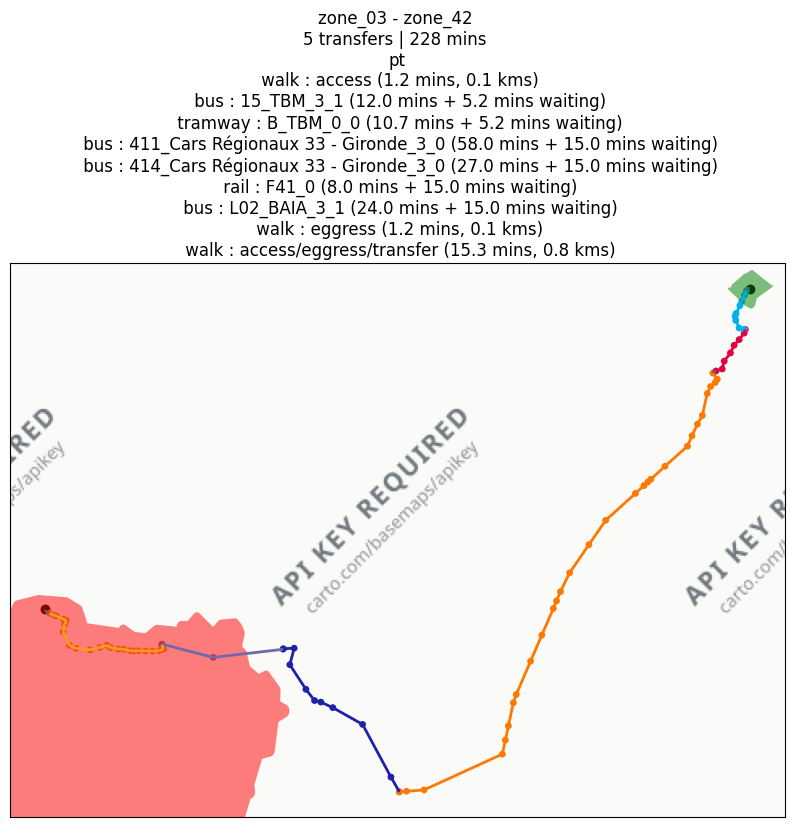

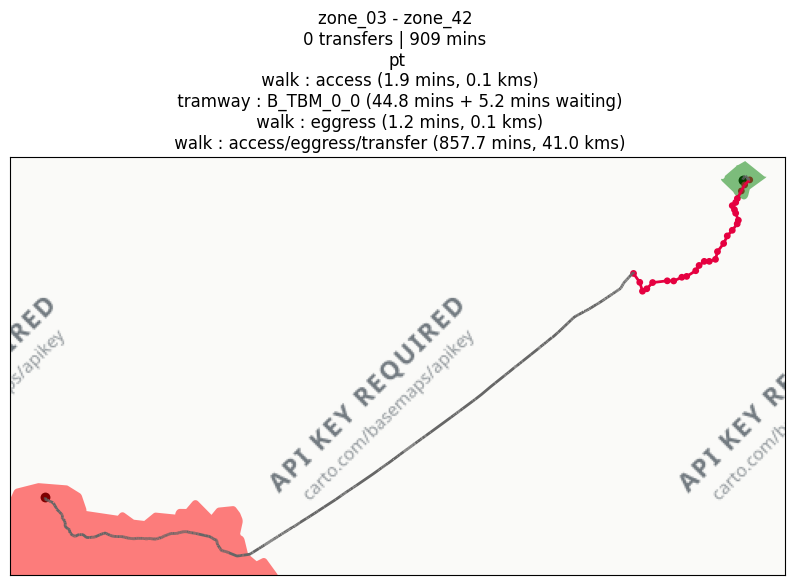

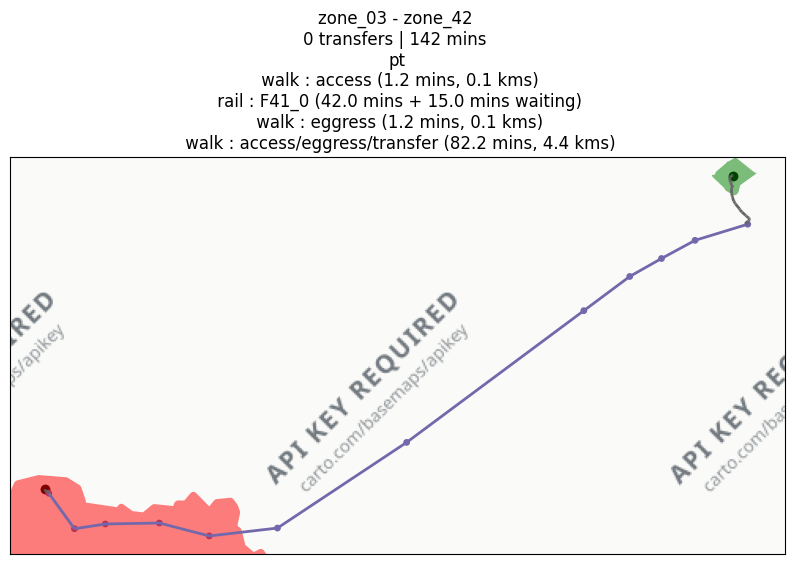

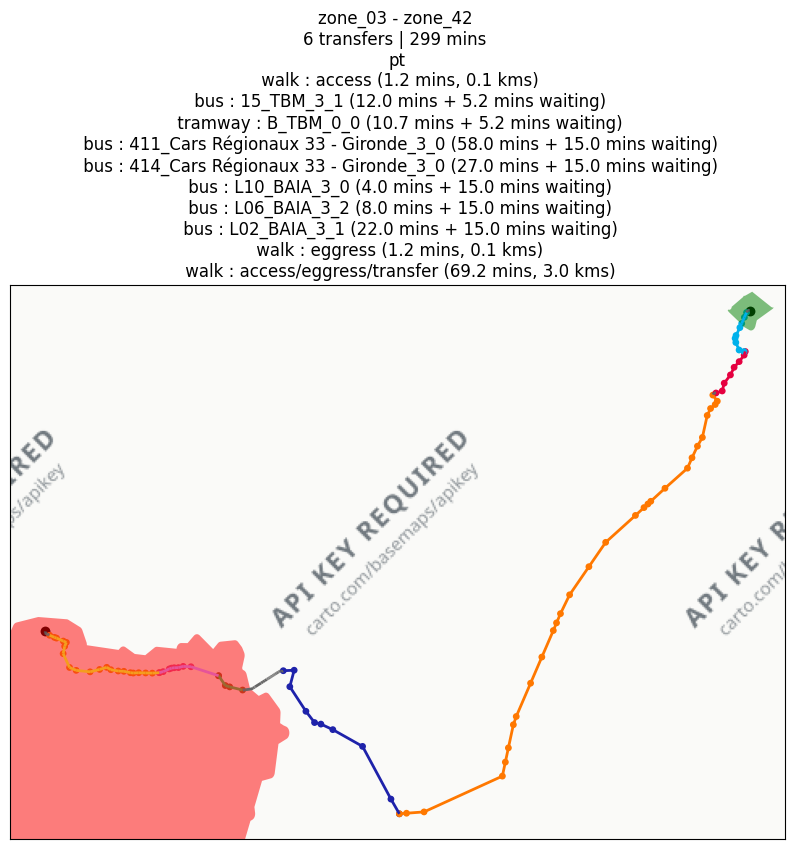

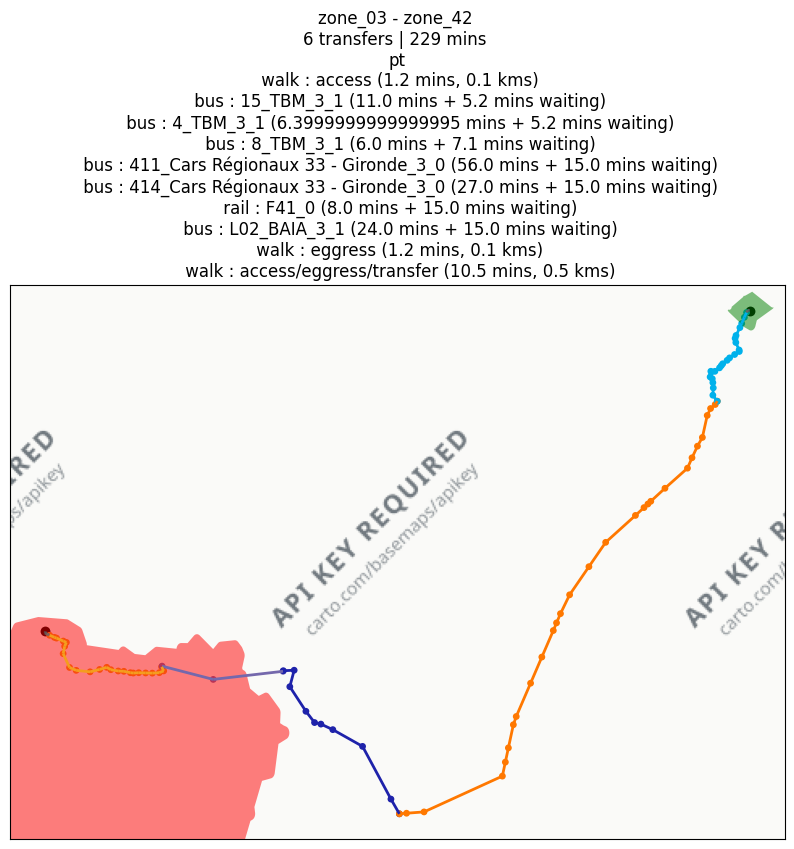

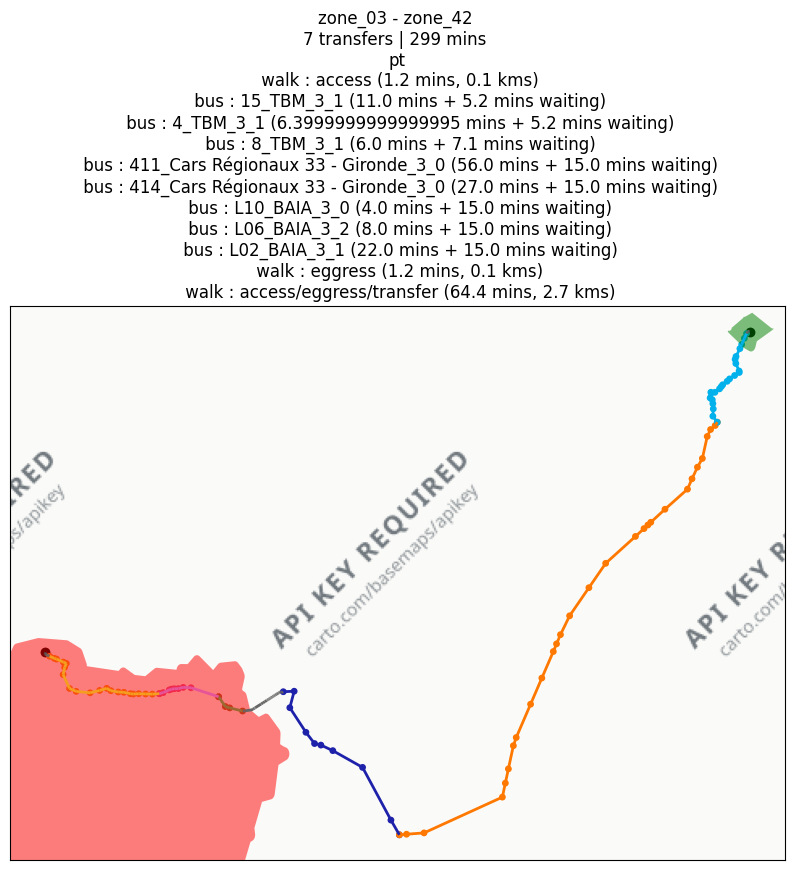

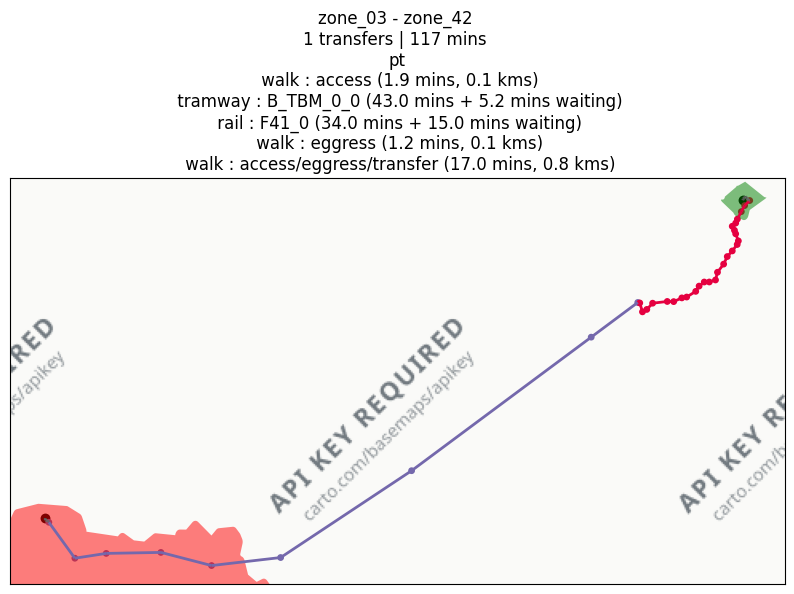

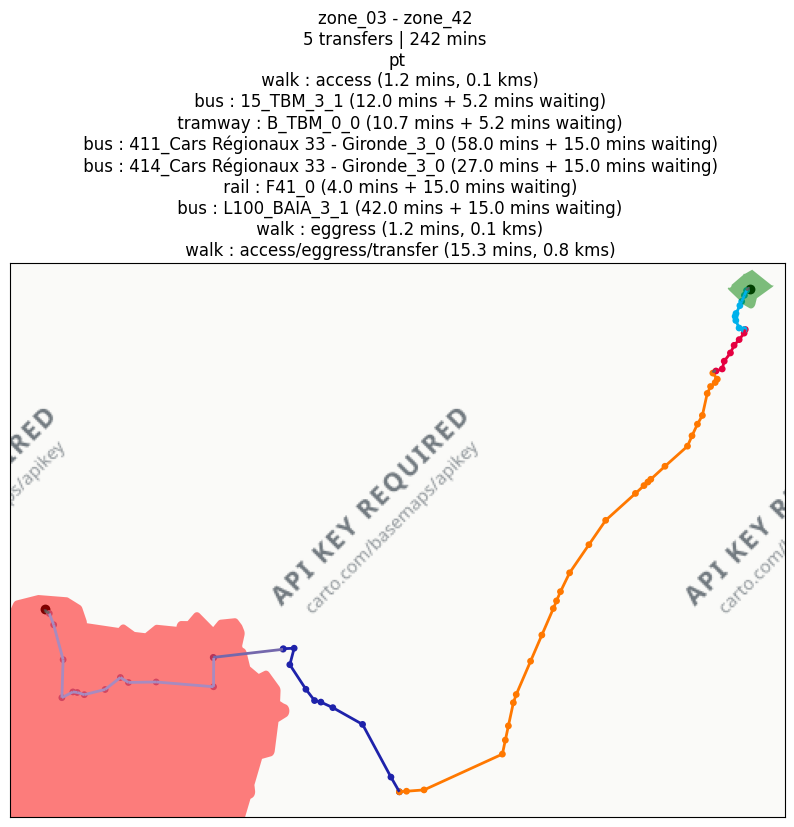

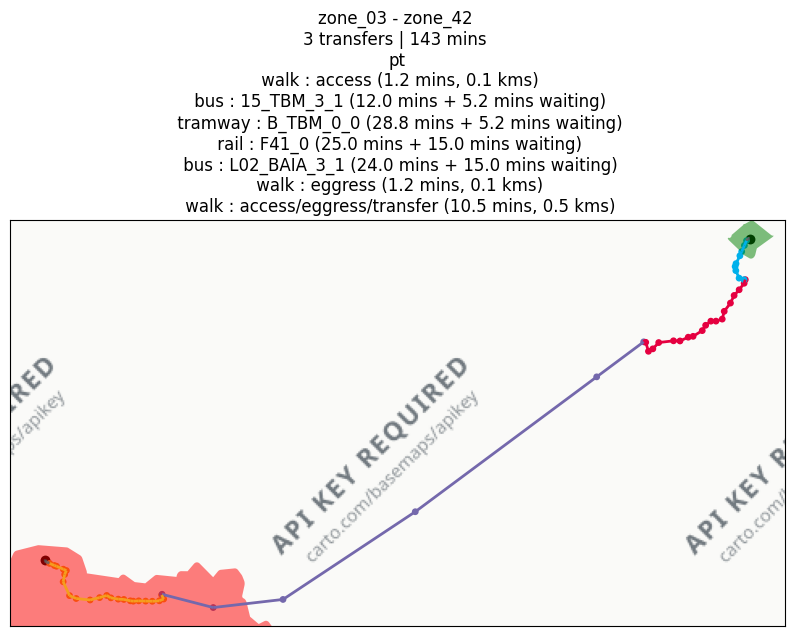

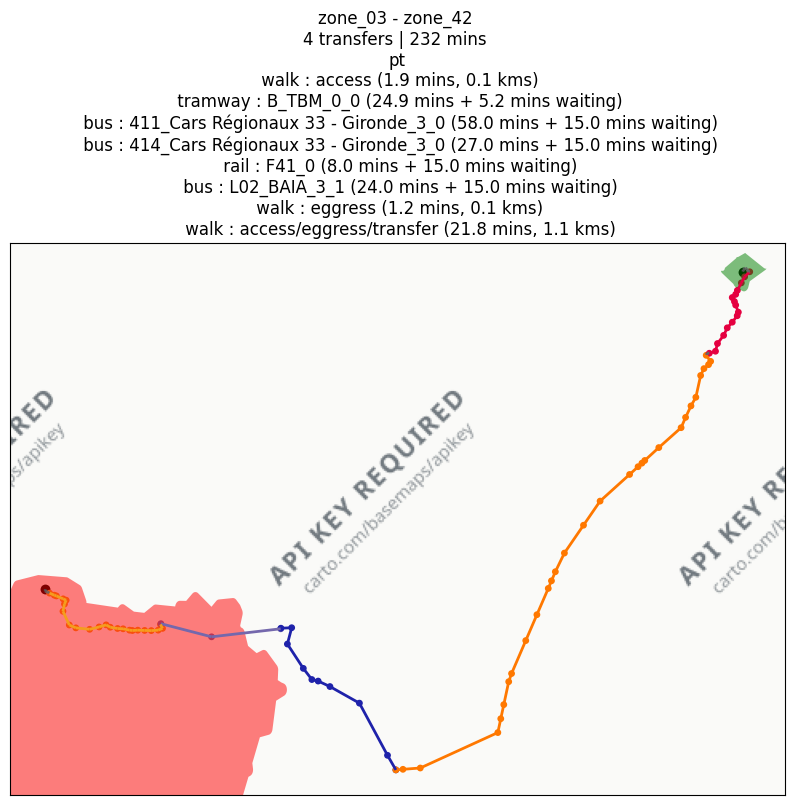

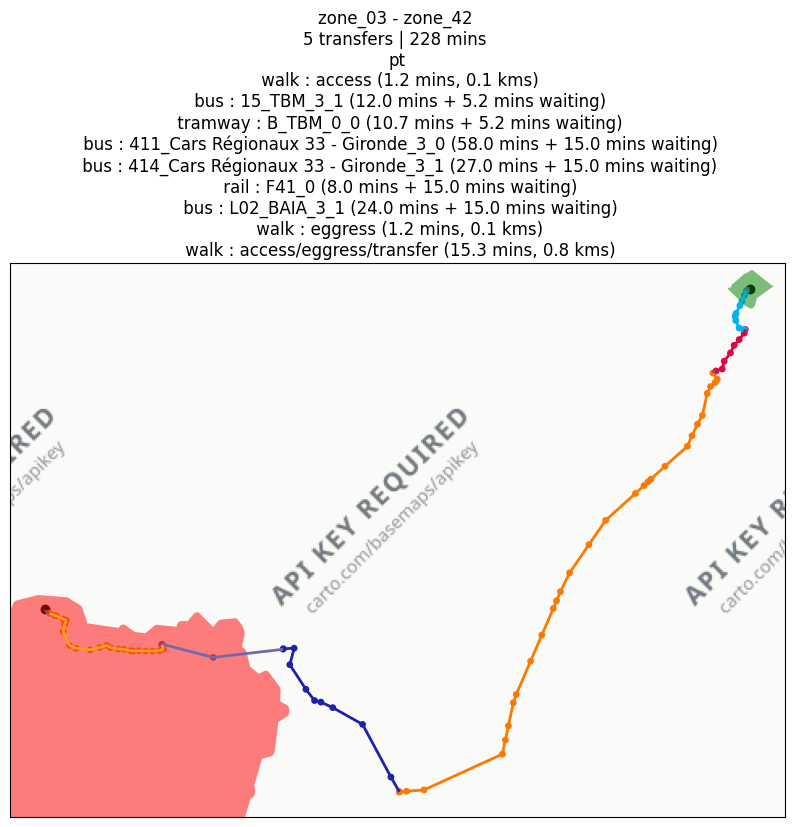

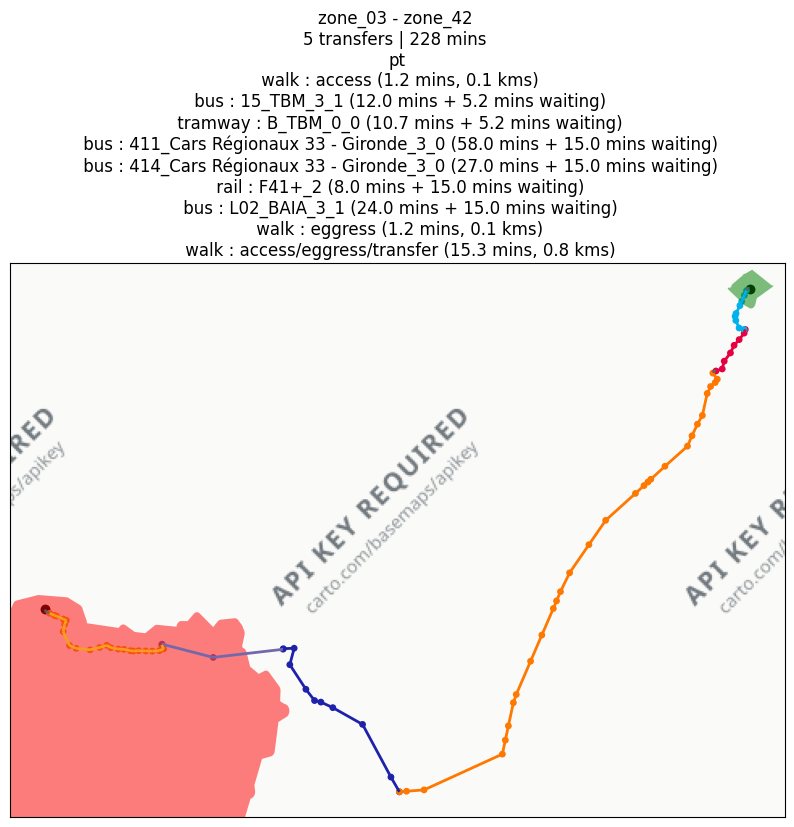

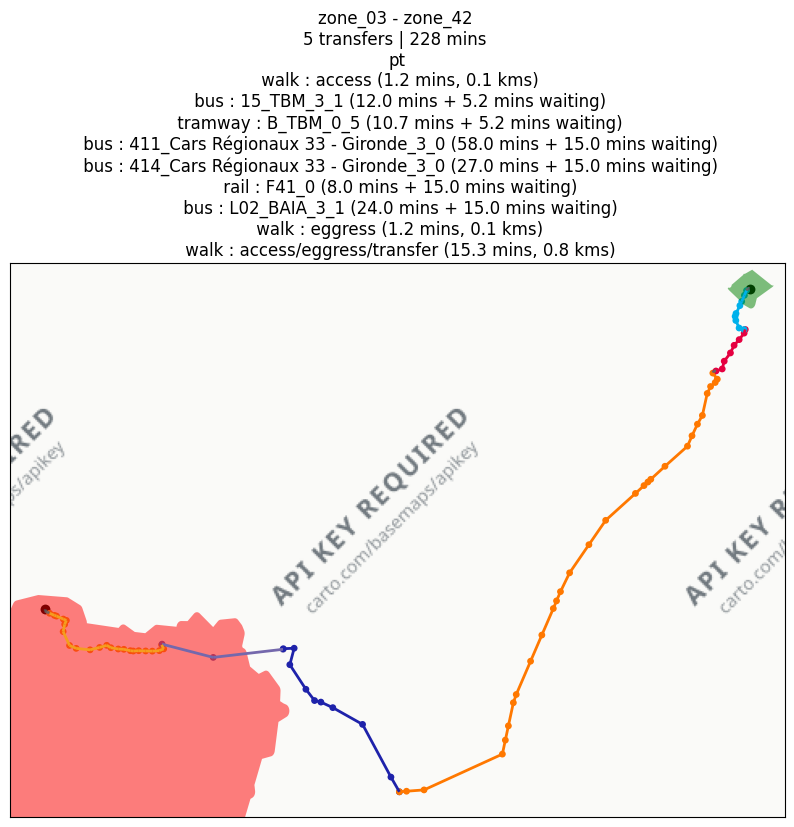

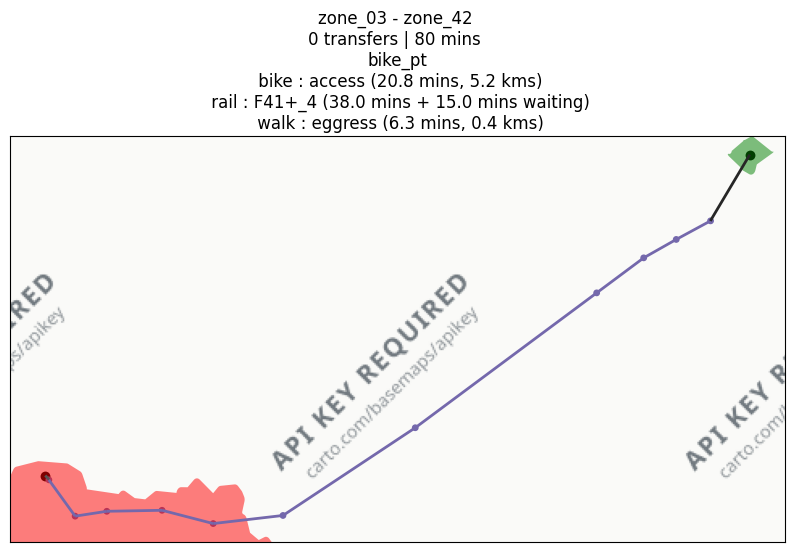

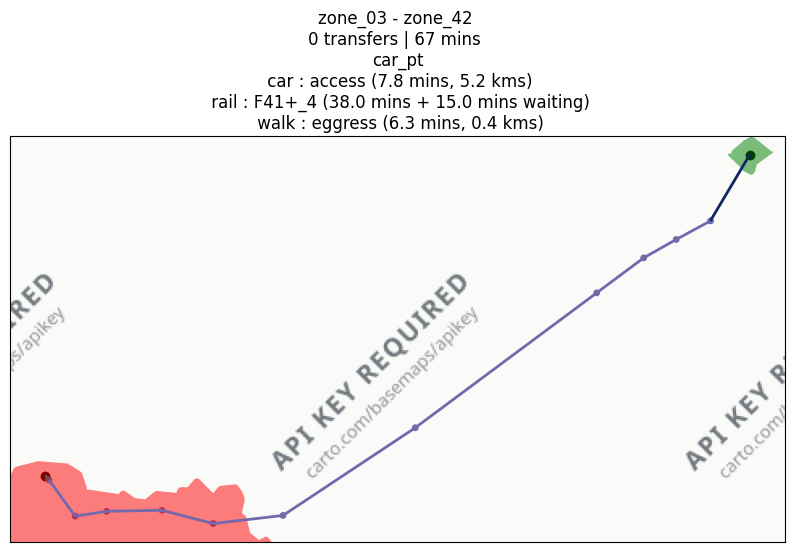

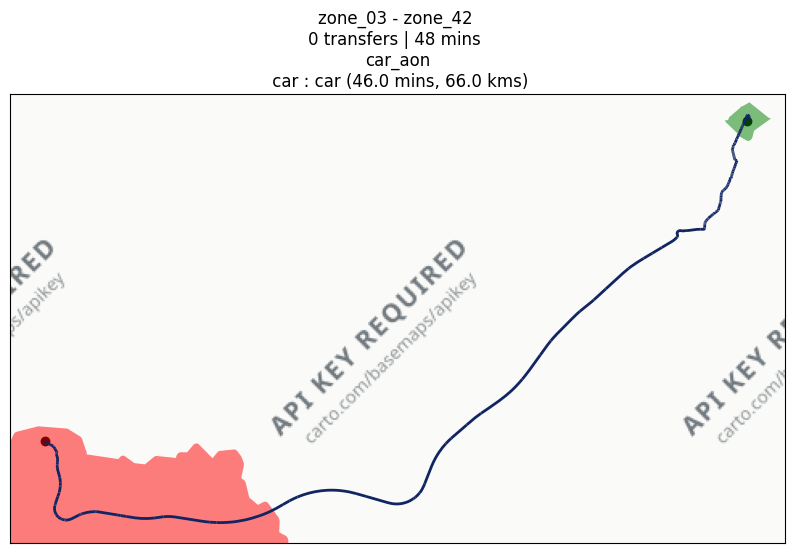

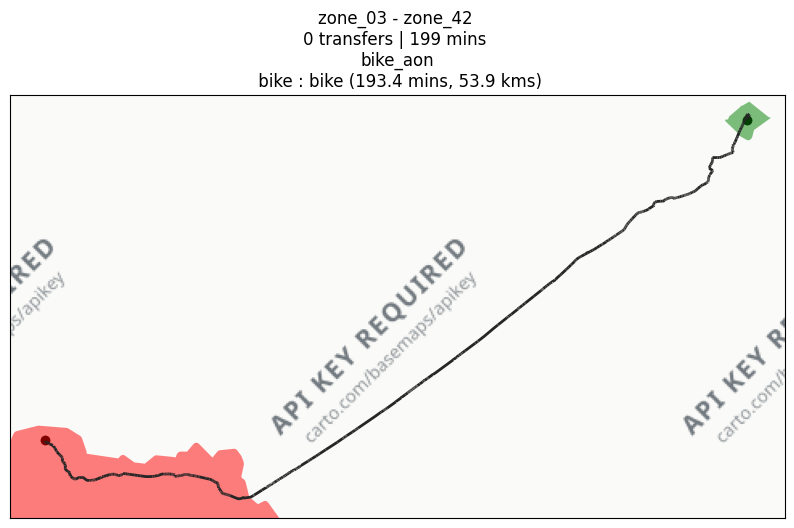

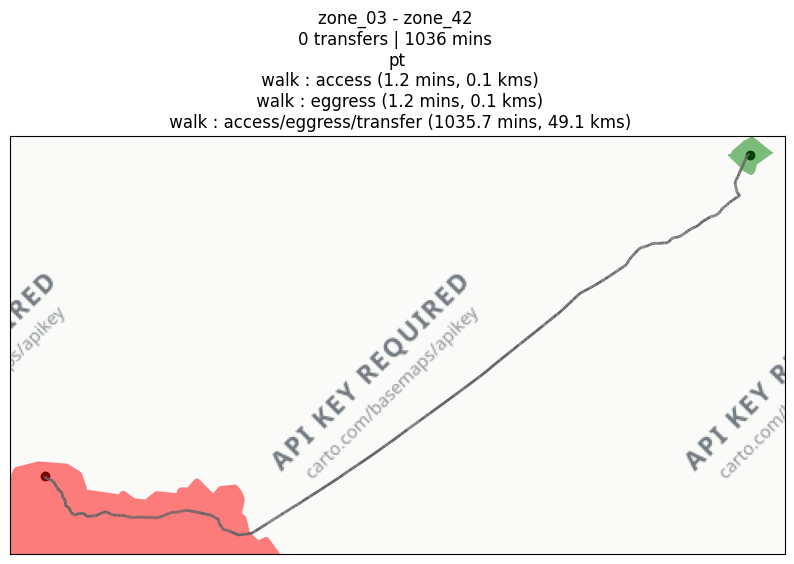

In [ ]:
from shapely.geometry import Point

origin = 'zone_03'
destination = 'zone_42'

route = od_route[(od_route['origin'] == origin) & (od_route['destination'] == destination)]
for journey in route['journey_id'].unique():
    fig, ax = plt.subplots(figsize=(10, 10))
    route_ = route.loc[route['journey_id'] == journey]
    pathfinder_session = route_['pathfinder_session'].values.tolist()[0]

    route_stations = route_.loc[route_['type'] == 'link'].copy()
    route_stations = route_stations[['route_color', 'geometry']]
    route_stations['node_from'] = route_stations['geometry'].apply(lambda x: Point(x.coords[0]))
    route_stations['node_to'] = route_stations['geometry'].apply(lambda x: Point(x.coords[-1]))
    route_stations_all = pd.concat([route_stations[['route_color', 'node_from']].rename(columns={'node_from': 'geometry'}), route_stations[['route_color', 'node_to']].rename(columns={'node_to': 'geometry'})])
    route_stations_all = route_stations_all.drop_duplicates()
    sm.od_basemap(origin=origin, destination=destination, squared=True, figsize=(10, 10), ax=ax)
    if len(route_stations_all) > 0:
        plot_points(route_stations_all, ax=ax, s=15, color=route_stations_all['route_color'])
    plot_lineStrings(route_, ax=ax, linewidth=2, colors=route_['route_color'])
    create_basemap(ax)
#    sm.zones.loc[[origin]].plot(ax=ax, color='green', alpha=0.5)
#    sm.zones.loc[[destination]].plot(ax=ax, color='red', alpha=0.5)
    zones_.to_crs(epsg=4326).loc[[origin]].plot(ax=ax, color='green', alpha=0.5)
    zones_.to_crs(epsg=4326).loc[[destination]].plot(ax=ax, color='red', alpha=0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    title = f'{origin} - {destination} \n'
    path = sm.los[sm.los['journey_id'] == journey].iloc[0]
    path['min'] = np.round(path['time'] / 60).astype(int)

    route_['time'] = np.round(route_['time']/60, 1)
    route_['headway'] = np.round(route_['headway']/120, 1)

    trip_mins = (route_.groupby('trip_id')['time'].sum()).to_dict()
    trip_wait_times = (route_.groupby('trip_id')['headway'].min()).to_dict()
    mode_mins = (route_.groupby('trip_id')['time'].sum()).to_dict()
    trip_to_modes = route_[['trip_id', 'route_type']].drop_duplicates().set_index('trip_id')['route_type'].to_dict()

    route_2154 = route_.to_crs(epsg=2154).copy()
    route_2154['distance'] = np.round((route_2154.length/1000), 1)
    trip_kms = (route_2154.groupby('trip_id')['distance'].sum()).to_dict()

    walking_links = route.loc[route['type']=='footpaths']
    if len(walking_links) >= 1:
        walking_distance = f"' ({int(walking_links['length'].sum()/1000)} kms)"
    else:
        walking_distance = "'"
    title += f'{path['ntransfers']} transfers | {path['min']} mins '
    title += '\n' + f'{pathfinder_session}'
    ### TODO: mins par mode
    ### TODO: ???
    
    trip_dict = sm.links['trip_id'].to_dict()
    trip_list = route_.loc[route_['type'] == 'link', 'index'].apply(trip_dict.get).drop_duplicates().dropna().to_list()

    if pathfinder_session in ['pt', 'car_pt', 'bike_pt']:
        trip_list = ['access'] + trip_list + ['eggress']
    if pathfinder_session == 'pt':
        trip_list += ['access/eggress/transfer']

    if pathfinder_session == 'car_aon':
        trip_list = ['car']

    if pathfinder_session == 'bike_aon':
        trip_list = ['bike']

    for trip in trip_list:
        title += f'\n {trip_to_modes[trip]} : {trip} ({trip_mins[trip]} mins'
        if trip_wait_times[trip] > 0:
            title += f' + {trip_wait_times[trip]} mins waiting)'
        elif trip_to_modes[trip] in ['walk', 'bike', 'car']:
            title += f', {trip_kms[trip]} kms)'
        else:
            title += ')'

    ax.set_title(title)